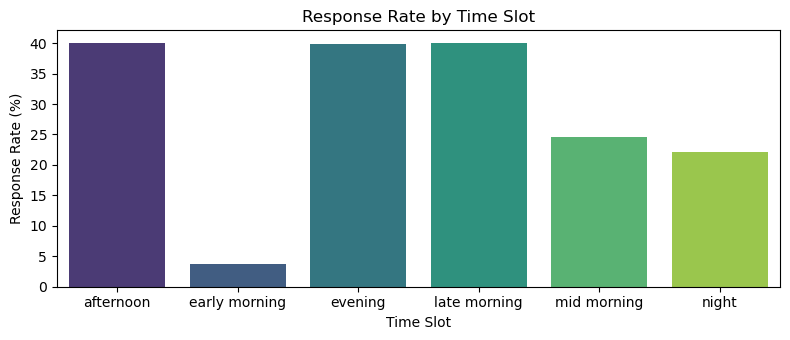

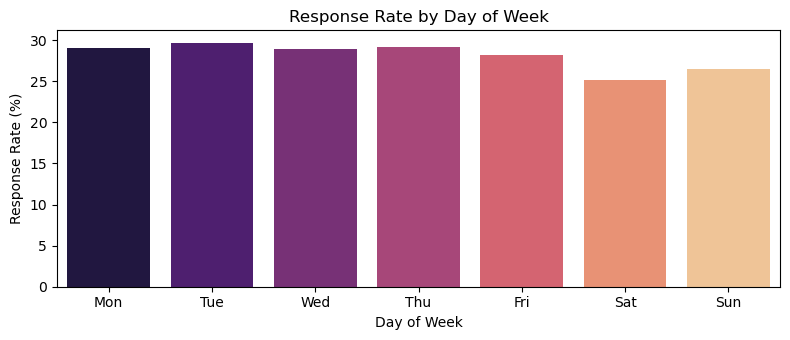

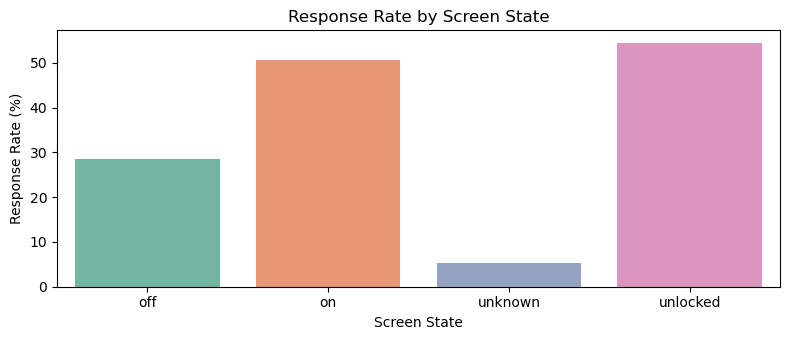

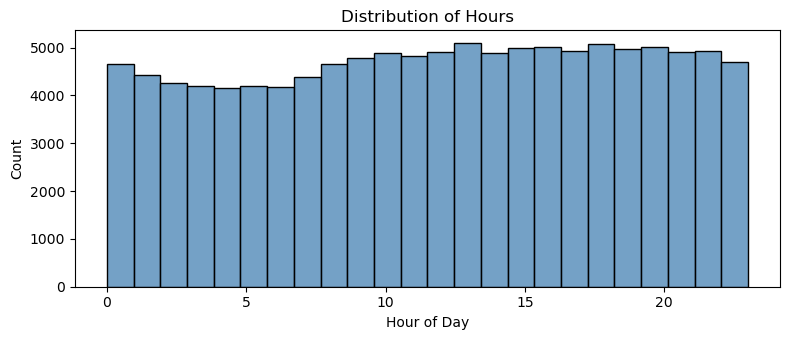

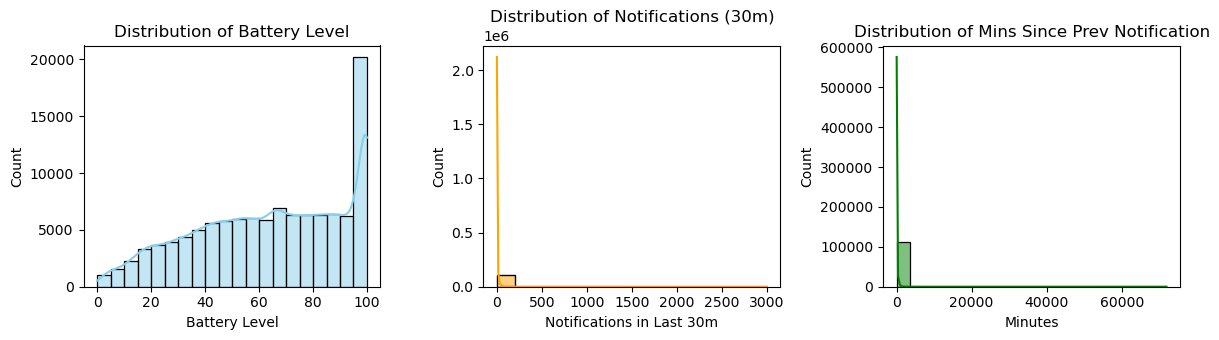

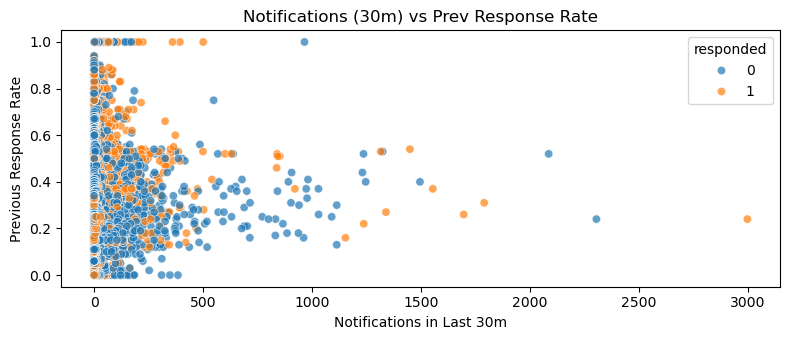

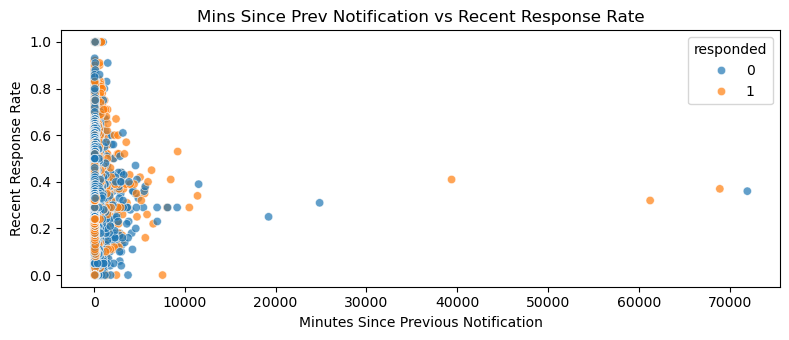

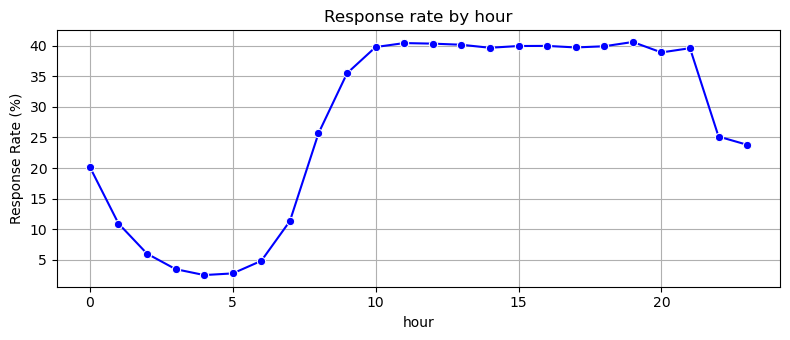

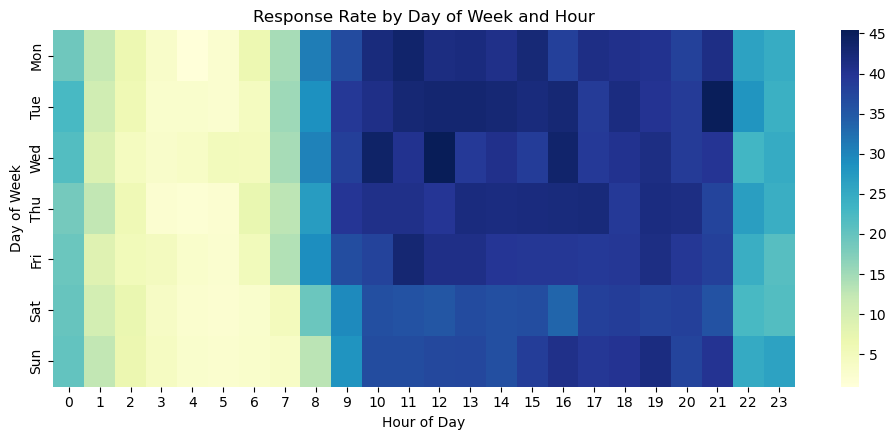

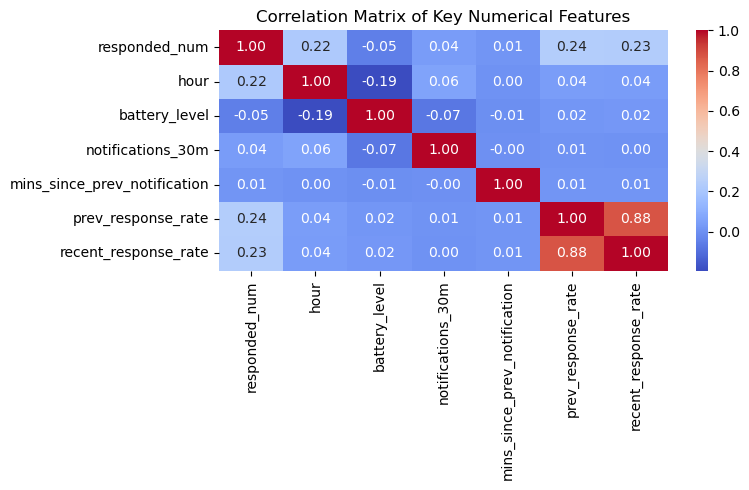

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('training_table.csv')

df['responded_num'] = pd.to_numeric(df['responded'], errors='coerce')

plt.figure(figsize=(8, 3.5))
df_slot = df.groupby('time_slot')['responded_num'].mean().reset_index()
df_slot['response_rate'] = df_slot['responded_num'] * 100
sns.barplot(data=df_slot, x='time_slot', y='response_rate', hue='time_slot', palette='viridis', legend=False)
plt.title('Response Rate by Time Slot')
plt.xlabel('Time Slot')
plt.ylabel('Response Rate (%)')
plt.tight_layout()
plt.show()

days_map = {0: 'Mon', 1: 'Tue', 2: 'Wed', 3: 'Thu', 4: 'Fri', 5: 'Sat', 6: 'Sun'}
plt.figure(figsize=(8, 3.5))
df_day = df.groupby('day_of_week')['responded_num'].mean().reset_index()
df_day['response_rate'] = df_day['responded_num'] * 100
df_day['day_name'] = df_day['day_of_week'].map(days_map)
sns.barplot(data=df_day, x='day_name', y='response_rate', hue='day_name', palette='magma', legend=False)
plt.title('Response Rate by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Response Rate (%)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 3.5))
df_screen = df.groupby('screen_state')['responded_num'].mean().reset_index()
df_screen['response_rate'] = df_screen['responded_num'] * 100
sns.barplot(data=df_screen, x='screen_state', y='response_rate', hue='screen_state', palette='Set2', legend=False)
plt.title('Response Rate by Screen State')
plt.xlabel('Screen State')
plt.ylabel('Response Rate (%)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 3.5))
sns.histplot(df['hour'], bins=24, kde=False, color='steelblue')
plt.title('Distribution of Hours')
plt.xlabel('Hour of Day')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
sns.histplot(df['battery_level'], bins=20, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Battery Level')
axes[0].set_xlabel('Battery Level')

sns.histplot(df['notifications_30m'], bins=15, kde=True, ax=axes[1], color='orange')
axes[1].set_title('Distribution of Notifications (30m)')
axes[1].set_xlabel('Notifications in Last 30m')

sns.histplot(df['mins_since_prev_notification'], bins=20, kde=True, ax=axes[2], color='green')
axes[2].set_title('Distribution of Mins Since Prev Notification')
axes[2].set_xlabel('Minutes')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 3.5))
sns.scatterplot(data=df, x='notifications_30m', y='prev_response_rate', hue='responded', alpha=0.7)
plt.title('Notifications (30m) vs Prev Response Rate')
plt.xlabel('Notifications in Last 30m')
plt.ylabel('Previous Response Rate')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 3.5))
sns.scatterplot(data=df, x='mins_since_prev_notification', y='recent_response_rate', hue='responded', alpha=0.7)
plt.title('Mins Since Prev Notification vs Recent Response Rate')
plt.xlabel('Minutes Since Previous Notification')
plt.ylabel('Recent Response Rate')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 3.5))
df_hourly = df.groupby('hour')['responded_num'].mean().reset_index()
df_hourly['response_rate'] = df_hourly['responded_num'] * 100
sns.lineplot(data=df_hourly, x='hour', y='response_rate', marker='o', color='blue')
plt.title('Response rate by hour')
plt.xlabel('hour')
plt.ylabel('Response Rate (%)')
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4.5))
heatmap_data = df.pivot_table(index='day_of_week', columns='hour', values='responded_num', aggfunc='mean') * 100
heatmap_data.index = [days_map[i] for i in heatmap_data.index]
sns.heatmap(heatmap_data, cmap='YlGnBu', annot=False)
plt.title('Response Rate by Day of Week and Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
key_features = ['responded_num', 'hour', 'battery_level', 'notifications_30m', 'mins_since_prev_notification', 'prev_response_rate', 'recent_response_rate']
corr_matrix = df[key_features].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Key Numerical Features')
plt.tight_layout()
plt.show()